# 10 — Time-varying Hungarian local-risk pricing

Audit the local instruments **before estimating** the new risk-price slopes. Keep the frozen
**321 months, 2000-01 through 2026-09**, paper-style FX means, existing time-varying world/FX prices,
and constant US local price. Use both retained covariance specifications: `scalar11` and `grouped21`
(two shock lags, one covariance lag). Run notebook 09 first, then **Run All** in the existing
Miniconda **base** kernel. All inputs are local; no API keys or downloads are needed.

The primary Hungarian local-price design is a constant, lagged inflation-gap change, and the
existing floating-regime indicator. A matched gap-level sensitivity is exploratory. The reusable
extension is [local_risk_pricing.py](local_risk_pricing.py); earlier engines, notebooks and outputs
are preserved.

In [1]:
SNAPSHOT="data/fixed_2026-11-13/from_2000-01"
UPSTREAM="output/09_covariance_robustness/fixed_2026-11-13/2000-01_2026-09/paper_fx_means"
COVARIANCE_MODELS=["scalar11","grouped21"]
LOCAL_INFLATION="change"  # primary: change or level; default retains the earlier stationarity choice
RUN_ALTERNATIVE_GAP=True  # matched opposite transformation, kept separate from the primary table
HAC_LAGS=[0,3,6,12]
TEST_LAGS=12
MAX_ITER=2400
SE_STEP_TOL=.01
REUSE_FITS=True
MODEL_VERSION="hungarian_local_risk_v1"

from pathlib import Path
from io import BytesIO
import hashlib,importlib,importlib.metadata,json,os,platform,sys,warnings
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from packaging.version import Version
if Version(importlib.metadata.version("statsmodels"))<Version("0.15.0"):raise RuntimeError("Update statsmodels to 0.15.0 and restart the same base kernel.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__!=importlib.metadata.version("statsmodels"):
    raise RuntimeError("Restart the same kernel to discard old statsmodels imports.")
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from IPython.display import display,Markdown
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pricing_robustness as base
import covariance_robustness as covariance
import local_risk_pricing as model
importlib.reload(base);importlib.reload(covariance);importlib.reload(model)
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib"]}
engine_hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in ["pricing_robustness.py","covariance_robustness.py","local_risk_pricing.py"]}
print("Python:",sys.executable);print("Packages:",versions)
if LOCAL_INFLATION not in ["change","level"]:raise ValueError("Choose change or level inflation gap.")
if not COVARIANCE_MODELS or len(set(COVARIANCE_MODELS))!=len(COVARIANCE_MODELS) or any(m not in ["scalar11","grouped21"] for m in COVARIANCE_MODELS):raise ValueError("Use the retained covariance models.")
if not HAC_LAGS or 0 not in HAC_LAGS or len(set(HAC_LAGS))!=len(HAC_LAGS) or any(type(h)!=int or h<0 for h in HAC_LAGS):raise ValueError("Include zero and distinct nonnegative integer HAC lags.")
pd.set_option("display.max_columns",18);pd.set_option("display.max_rows",50)
pd.options.display.float_format=lambda x:f"{x:.6g}"
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.16})
source,upstream=ROOT/SNAPSHOT,ROOT/UPSTREAM
manifest=json.loads((source/"manifest.json").read_text());raw=(source/"dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest()!=manifest["exports"]["dataset.csv"]:raise ValueError("Frozen dataset checksum differs.")
data=pd.read_csv(BytesIO(raw),index_col=0,float_precision="round_trip");data.index=pd.PeriodIndex(data.index,freq="M",name="month")
if not data.index.equals(pd.period_range(data.index[0],data.index[-1],freq="M")):raise ValueError("Discontinuous model months.")
if max(HAC_LAGS)>=len(data):raise ValueError("HAC bandwidth exceeds the sample.")
upstream_hashes,conditioning_hashes={},{}
def upstream_bytes(name):
    content=(upstream/name).read_bytes();upstream_hashes[name]=hashlib.sha256(content).hexdigest();return content
prior=json.loads(upstream_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["first"]!=str(data.index[0]) or prior["last"]!=str(data.index[-1]) or prior["observations"]!=len(data)):
    raise ValueError("Notebook 09 sample differs.")
for p,digest in prior["engines"].items():
    if engine_hashes[p]!=digest:raise ValueError("An upstream likelihood engine changed.")
previous_root=ROOT/prior["upstream"];content=(previous_root/"estimation_manifest.json").read_bytes()
if hashlib.sha256(content).hexdigest()!=prior["upstream_file_sha256"]["estimation_manifest.json"]:raise ValueError("Notebook 08 provenance changed.")
previous=json.loads(content);conditioning_root=ROOT/previous["upstream"]
def conditioning_bytes(name):
    content=(conditioning_root/name).read_bytes();digest=hashlib.sha256(content).hexdigest()
    if digest!=prior["conditioning_file_sha256"][name]:raise ValueError(f"Conditioning checksum differs: {name}")
    conditioning_hashes[name]=digest;return content
inflation=pd.read_csv(BytesIO(conditioning_bytes("inflation_reconstruction.csv")),index_col=0,float_precision="round_trip")
inflation.index=pd.PeriodIndex(inflation.index,freq="M")
quality=pd.read_csv(BytesIO(conditioning_bytes("conditioning_quality_flags.csv")),index_col=[0,1])
normalizers=pd.read_csv(BytesIO(conditioning_bytes("instrument_normalizers.csv")),index_col=[0,1,2],float_precision="round_trip").sort_index()
old_summary=pd.read_csv(BytesIO(upstream_bytes("model_comparison.csv")),index_col=0,float_precision="round_trip")
samples,designs,design_columns,references,local_frames={}, {}, {}, {}, {}
for currency,gap in [("USD","US_HU"),("EUR","EA_HU")]:
    designs[currency],design_columns[currency]={},{}
    for label in ["W","H","O"]:
        z=pd.read_csv(BytesIO(conditioning_bytes(f"conditioning_{currency.lower()}_{label}.csv")),index_col=0,float_precision="round_trip")
        if not pd.PeriodIndex(z.index,freq="M").equals(data.index):raise ValueError("Conditioning months differ.")
        designs[currency][label]=z.to_numpy();design_columns[currency][label]=list(z.columns)
        if label=="H":
            stats=normalizers.loc[(currency,label)].reindex(z.columns[1:])
            recovered=pd.DataFrame(z.iloc[:,1:].to_numpy()*stats["sd"].to_numpy()+stats["mean"].to_numpy(),index=data.index,columns=z.columns[1:])
            np.testing.assert_allclose(recovered["HUF_inflation_gap_change_lag2_pp"],inflation[f"change_{gap}_lag2_pp"],atol=1e-12,rtol=0)
    np.testing.assert_allclose(inflation[f"level_{gap}_lag2_pp"],data[f"inflation_gap_{currency.lower()}_lag2_pp"],atol=1e-12,rtol=0)
    np.testing.assert_allclose(inflation[f"change_{gap}_lag2_pp"].iloc[1:],inflation[f"level_{gap}_lag2_pp"].diff().iloc[1:],atol=1e-12,rtol=0)
    local_frames[currency]={t:pd.DataFrame({f"inflation_gap_{t}_lag2_pp":inflation[f"{t}_{gap}_lag2_pp"],"floating_regime_known":data["floating_regime_known"]},index=data.index) for t in ["change","level"]}
    equity=data[[f"rx_{a}_{currency.lower()}" for a in ["world","us","hu"]]].to_numpy()*100
    fx=np.c_[data[f"fx_huf_{currency.lower()}"]*100,data["fx_eur_usd"]*100*(1 if currency=="USD" else -1)]
    samples[currency]=np.c_[equity,fx]
    for name in COVARIANCE_MODELS:
        with np.load(BytesIO(upstream_bytes(f"parameters_{currency}_{name}.npz")),allow_pickle=False) as a:references[(currency,name)]={k:a[k].copy() for k in a.files}
np.testing.assert_array_equal(data["floating_regime_known"],(data.index>=pd.Period("2008-03",freq="M")).astype(int))
OUT=ROOT/"output"/"10_time_varying_local"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/f"local_{LOCAL_INFLATION}"
OUT.mkdir(parents=True,exist_ok=True)

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


## 1. Audit timing, persistence and collinearity first

For investor $c$, the annual inflation gap is $g^c_t=\pi^c_t-\pi^{HU}_t$. The primary continuous
conditioner is **$g^c_{t-2}-g^c_{t-3}$**, matching the audited currency-price transformation; the
alternative is **$g^c_{t-2}$**. Both use the same frozen inflation reconstruction. Two-month lagging
is a publication-lag convention, **not a real-time vintage guarantee**: historical source data may
have been revised. No return, price or missing CPI index is interpolated here. The carried US annual
inflation rate already documented in notebook 07 is flagged for each affected local design.

The regime indicator is one from **March 2008**, the first full month after the
[MNB's February 26 float](https://www.mnb.hu/en/monetary-policy/monetary-policy-framework/exchange-rate-regime).
It is a regime proxy; it does not measure foreign-ownership liberalization or identify its causal effect.
Both perspectives have 98 pre-float and 223 floating-regime observations. Do not unit-root-test a
binary policy indicator.

[ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html) has a
unit-root null; [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html)
has a level-stationarity null here. ADF uses a constant, AIC lag choice up to 12; KPSS uses a constant
and automatic bandwidth. Display boundary-censored KPSS p-values honestly. The gap levels have
mixed stationarity evidence; retain changes as the primary choice established earlier, with levels
as an exploratory sensitivity. These tests do not establish economic relevance.

Audit rank, standardized condition number and VIF before fitting. World/FX conditioners stay fixed.
Shared inflation/regime predictors across FX and local prices are allowed; these are conditioning
variables in joint QML, not excluded IV instruments. Also inspect the full mean-loading matrix
holding notebook 09 covariances fixed. This is a preliminary collinearity screen; joint curvature and
SE stability after re-estimation still determine whether inference is reported.

In [2]:
local_designs={c:{} for c in ["USD","EUR"]}
normalizer_rows,audit_rows,design_rows,flag_rows=[],[],[],[]
for currency in ["USD","EUR"]:
    for transform,frame in local_frames[currency].items():
        mean,sd=frame.mean(),frame.std(ddof=1)
        z=np.c_[np.ones(len(frame)),((frame-mean)/sd).to_numpy()]
        if not np.isfinite(z).all() or np.linalg.matrix_rank(z)!=z.shape[1]:raise ValueError("Invalid local design.")
        local_designs[currency][transform]=z
        design_rows.append({"perspective":currency,"transform":transform,"n":len(z),"rank":np.linalg.matrix_rank(z),"columns":z.shape[1],"condition":np.linalg.cond(z),"maximum_VIF":max(variance_inflation_factor(z,i) for i in range(1,z.shape[1]))})
        for name in frame:
            normalizer_rows.append({"perspective":currency,"transform":transform,"instrument":name,"mean":mean[name],"sd":sd[name]})
            s=frame[name];row={"perspective":currency,"transform":transform,"instrument":name,"n":len(s),"missing":int(s.isna().sum()),"mean":s.mean(),"sd":s.std(ddof=1),"min":s.min(),"max":s.max(),"AR1":s.autocorr()}
            if name=="floating_regime_known":row.update(ADF_p=np.nan,KPSS_p=np.nan,KPSS_p_note="binary regime: not tested",zeros=int((s==0).sum()),ones=int((s==1).sum()))
            else:
                a=adfuller(s,maxlag=12,regression="c",autolag="AIC",result_object=False)
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always");k=kpss(s,regression="c",nlags="auto")
                note="at least 0.10" if k[1]==.1 and caught else "at most 0.01" if k[1]==.01 and caught else "reported p-value"
                row.update(ADF_p=a[1],ADF_lags=a[2],KPSS_p=k[1],KPSS_lags=k[2],KPSS_p_note=note)
            audit_rows.append(row)
        carry=data["flag_us_inflation_carried_lag2"].astype(bool) if currency=="USD" else pd.Series(False,index=data.index)
        affected=(carry|carry.shift(1,fill_value=False)) if transform=="change" else carry
        if transform=="change":np.testing.assert_array_equal(affected,quality.loc[currency,"HUF_inflation_uses_carried_US_rate"].astype(bool))
        flag_rows.extend({"perspective":currency,"transform":transform,"month":str(month),"carried_US_inflation_used":bool(v)} for month,v in affected.items())
instrument_audit=pd.DataFrame(audit_rows);design_audit=pd.DataFrame(design_rows)
local_normalizers=pd.DataFrame(normalizer_rows);local_quality=pd.DataFrame(flag_rows)
display(instrument_audit);display(design_audit)
display(local_quality[local_quality["carried_US_inflation_used"]])
print("Audit decision: use",LOCAL_INFLATION,"plus the regime indicator as primary; keep the opposite gap transformation separate.")

,perspective,transform,instrument,n,missing,mean,sd,min,max,AR1,ADF_p,ADF_lags,KPSS_p,KPSS_lags,KPSS_p_note,zeros,ones
0,USD,change,inflation_gap_change_lag2_pp,321,0,0.0301286,0.771611,-4.20478,3.77443,0.551572,3.84579e-10,12,0.1,9,at least 0.10,NaN,NaN
1,USD,change,floating_regime_known,321,0,0.694704,0.461252,0,1,0.992652,NaN,NaN,NaN,NaN,binary regime: not tested,98,223
2,USD,level,inflation_gap_level_lag2_pp,321,0,-2.60055,3.73889,-20.6353,2.19362,0.978597,0.10761,12,0.1,10,at least 0.10,NaN,NaN
3,USD,level,floating_regime_known,321,0,0.694704,0.461252,0,1,0.992652,NaN,NaN,NaN,NaN,binary regime: not tested,98,223
4,EUR,change,inflation_gap_change_lag2_pp,321,0,0.0327103,0.681366,-3.66327,3.22242,0.420178,1.84255e-09,12,0.1,8,at least 0.10,NaN,NaN
5,EUR,change,floating_regime_known,321,0,0.694704,0.461252,0,1,0.992652,NaN,NaN,NaN,NaN,binary regime: not tested,98,223
6,EUR,level,inflation_gap_level_lag2_pp,321,0,-3.05221,3.2484,-18.7361,1.29935,0.977821,0.108811,12,0.1,10,at least 0.10,NaN,NaN
7,EUR,level,floating_regime_known,321,0,0.694704,0.461252,0,1,0.992652,NaN,NaN,NaN,NaN,binary regime: not tested,98,223


,perspective,transform,n,rank,columns,condition,maximum_VIF
0,USD,change,321,3,3,1.01494,1.00022
1,USD,level,321,3,3,1.22442,1.04156
2,EUR,change,321,3,3,1.01677,1.00028
3,EUR,level,321,3,3,1.30788,1.07379


,perspective,transform,month,carried_US_inflation_used
311,USD,change,2025-12,True
312,USD,change,2026-01,True
632,USD,level,2025-12,True


Audit decision: use change plus the regime indicator as primary; keep the opposite gap transformation separate.


## 2. Add the Hungarian local-price slopes

Following the supplied draft's equation (17) and Table 7, extend only the Hungarian local price.
With the default change design:

$$\boxed{\lambda_{HU,t}=\kappa_{HU,0}+\kappa_{HU,\pi}\widetilde{\Delta g^c_{t-2}}
+\kappa_{HU,D}\widetilde D_t.}$$

Tildes mean full-working-sample demeaning and standardization. Thus the intercept equals the
sample-average fitted local price; this scaling is in-sample normalization, not an out-of-sample fit.
The inflation change and Hungary's floating-regime proxy adapt the draft's inflation-gap level and
Finnish liberalization dummy. The gap-level alternative changes **only the local-price inflation
transform**, leaving FX-price conditioners fixed. See the
[available draft](https://www.efmaefm.org/0EFMAMEETINGS/EFMA%20ANNUAL%20MEETINGS/2005-Milan/papers/14-antell_paper.pdf).

The Hungarian conditional mean is

$$\boxed{\mu_{HU,t}=\lambda_{W,t}H_{HU,W,t}+\lambda_{H,t}H_{HU,H,t}
+\lambda_{O,t}H_{HU,O,t}+\lambda_{HU,t}H_{HU,HU,t}.}$$

This uses Hungary's **own conditional variance**, consistently with the earlier model; it is not an
orthogonalized residual variance. The US local price remains constant. All five equations and the
covariance recursion are jointly re-estimated; no two-step regression treats estimated covariances
as known. Mean-loadings below are audit diagnostics only.

Constant local pricing nests exactly at both new slopes zero. Risk coefficients are optimized in
units of 0.01 and exports restore their economic units. Parameter counts: scalar **34 → 36**,
grouped two-shock-lag **41 → 43**. Local prices are linear and unrestricted in sign.

In [3]:
def make_case(currency,name,specification):
    pdsg={a:z.copy() for a,z in designs[currency].items()}
    pdsg["L"]=np.ones((len(data),1)) if specification=="constant" else local_designs[currency][specification].copy()
    columns={**design_columns[currency],"L":["constant"]+([] if specification=="constant" else list(local_frames[currency][specification].columns))}
    y=samples[currency]
    return {"columns":columns,"id":f"{currency}_{name}_{specification}","currency":currency,"name":name,"specification":specification,"y":y,"pdesign":pdsg,"scales":y.std(axis=0,ddof=1)}
def args(case):return (case["y"],case["pdesign"],case["scales"],case["name"])
loading_rows,checks=[],[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        saved=references[(currency,name)];constant=make_case(currency,name,"constant");f=model.filter_model(saved["theta"],*args(constant))
        for new,old in [("H","H"),("mu","mu"),("errors","residuals"),("scores","scores")]:np.testing.assert_allclose(f[new],saved[old],atol=1e-8,rtol=1e-9)
        np.testing.assert_allclose(-f["losses"].sum(),old_summary.loc[f"{currency}_{name}","loglik"],atol=1e-8,rtol=0)
        for transform in ["change","level"]:
            case=make_case(currency,name,transform);theta=model.expand_constant(saved["theta"],case["pdesign"])
            nested=model.filter_model(theta,*args(case))
            for key in ["H","mu","losses"]:np.testing.assert_allclose(nested[key],f[key],atol=1e-9,rtol=1e-11)
            indices=model.price_indices(case["pdesign"]);k=model.layout(case["pdesign"],name)[0]
            M=np.zeros((len(data),5,k))
            for label,factor in [("W",0),("H",3),("O",4)]:M[:,:,indices[label]]=saved["H"][:,:,factor,None]*case["pdesign"][label][:,None,:]
            M[:,1,1]=saved["H"][:,1,1]
            M[:,2,indices["L"]]=saved["H"][:,2,2,None]*case["pdesign"]["L"]
            flat=M.reshape(-1,k);scaled=flat/np.linalg.norm(flat,axis=0)
            rank=np.linalg.matrix_rank(scaled);condition=np.linalg.cond(scaled)
            if rank!=k or not np.isfinite(condition):raise ValueError("Rank-deficient mean-loading design.")
            loading_rows.append({"perspective":currency,"covariance":name,"transform":transform,"rank":rank,"columns":k,"column_scaled_condition":condition})
            probe=model.initial_theta(*args(case))
            probe[indices["L"][1:]]=[.15,-.10]
            sub=(case["y"][:35],{a:z[:35] for a,z in case["pdesign"].items()},case["scales"],name)
            analytical=model.objective(probe,*sub)[1];numeric=base.numerical_gradient(lambda t:model.objective(t,*sub)[0],probe)
            np.testing.assert_allclose(analytical,numeric,atol=5e-6,rtol=5e-5)
            checks.append({"perspective":currency,"covariance":name,"transform":transform,"gradient_error":np.max(np.abs(analytical-numeric))})
mean_loading_audit=pd.DataFrame(loading_rows)
display(mean_loading_audit.round(4));display(pd.DataFrame(checks))

,perspective,covariance,transform,rank,columns,column_scaled_condition
0,USD,scalar11,change,19,19,31.0699
1,USD,scalar11,level,19,19,31.013
2,USD,grouped21,change,19,19,28.9609
3,USD,grouped21,level,19,19,28.8886
4,EUR,scalar11,change,19,19,8.4859
5,EUR,scalar11,level,19,19,8.5158
6,EUR,grouped21,change,19,19,7.7307
7,EUR,grouped21,level,19,19,7.7452


,perspective,covariance,transform,gradient_error
0,USD,scalar11,change,1.35593e-08
1,USD,scalar11,level,1.36829e-08
2,USD,grouped21,change,1.18516e-08
3,USD,grouped21,level,1.165e-08
4,EUR,scalar11,change,2.34586e-08
5,EUR,scalar11,level,2.33625e-08
6,EUR,grouped21,change,1.92749e-08
7,EUR,grouped21,level,1.9448e-08


## 3. Estimate matched constant and time-varying cases

The four constant-price cases reproduce notebook 09. For each new case use that nested estimate
and an independent moment-based start. Re-estimate all mean/covariance parameters. Reject incomplete
optimization or a lower unconverged candidate; retain bounds/weak curvature for audit while
withholding ordinary inference. Verified caches include input arrays, all three engine hashes,
optimizer settings and package versions. Set `REUSE_FITS=False` for a full re-estimation.

In [4]:
fits,start_rows={},[]
transforms=[LOCAL_INFLATION]+(["level" if LOCAL_INFLATION=="change" else "change"] if RUN_ALTERNATIVE_GAP else [])
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        for specification in ["constant"]+transforms:
            case=make_case(currency,name,specification);key=case["id"];print(key,flush=True)
            if specification=="constant":
                theta=references[(currency,name)]["theta"]
                case.update(theta=theta,filter=model.filter_model(theta,*args(case)),origin="verified notebook 09")
                fits[key]=case;print("  verified upstream reference",flush=True);continue
            config={"version":MODEL_VERSION,"engines":engine_hashes,"source_sha256":manifest["exports"]["dataset.csv"],"case":key,
                "first":str(data.index[0]),"last":str(data.index[-1]),"n":len(data),"python":platform.python_version(),"packages":versions,
                "max_iter":MAX_ITER,"starts":["nested constant local price","independent moment start"],"upstream_sha256":upstream_hashes,"conditioning_sha256":conditioning_hashes}
            payload=json.dumps(config,sort_keys=True).encode()+case["y"].tobytes()+b"".join(case["pdesign"][a].tobytes() for a in ["W","H","O","L"])
            fingerprint=hashlib.sha256(payload).hexdigest();path=OUT/f"fit_{key}.json"
            cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
            limits=model.bounds(case["pdesign"],name);candidate=np.asarray(cached["theta"]) if cached else np.array([])
            record=None
            if candidate.shape==(len(limits),) and cached.get("fingerprint")==fingerprint and np.isfinite(candidate).all() and (candidate>=limits[:,0]).all() and (candidate<=limits[:,1]).all():
                value,gradient=model.objective(candidate,*args(case))
                if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(gradient))<1e-4:record=cached;print("  verified cached fit",flush=True)
            starts=[model.expand_constant(references[(currency,name)]["theta"],case["pdesign"]),model.initial_theta(*args(case))]
            if record is None:
                best,runs=model.fit_starts(args(case),starts,maxiter=MAX_ITER)
                record={"fingerprint":fingerprint,"configuration":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"starts":runs}
                path.write_text(json.dumps(record,indent=2)+"\n")
            for row in record["starts"]:start_rows.append({"case":key,**row})
            theta=np.asarray(record["theta"]);case.update(theta=theta,filter=model.filter_model(theta,*args(case)),origin="joint re-estimation")
            parent=fits[f"{currency}_{name}_constant"]
            if case["filter"]["losses"].sum()>parent["filter"]["losses"].sum()+1e-5:raise ValueError("Expanded fit is worse than its nested constant-price case.")
            fits[key]=case
starting_points=pd.DataFrame(start_rows);display(starting_points)

USD_scalar11_constant


  verified upstream reference


USD_scalar11_change


  verified cached fit


USD_scalar11_level


  verified cached fit


... (15 outputs left out)

  verified cached fit


EUR_grouped21_level


  verified cached fit


,case,start,success,mean_nll,max_abs_gradient,iterations,message
0,USD_scalar11_change,1,True,11.5861,3.67277e-06,130,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
1,USD_scalar11_change,2,True,11.5861,3.15969e-06,253,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
2,USD_scalar11_level,1,True,11.5849,3.17824e-06,152,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
3,USD_scalar11_level,2,True,11.5849,1.02128e-05,251,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
4,USD_grouped21_change,1,True,11.5617,7.98959e-07,167,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
5,USD_grouped21_change,2,True,11.5617,9.30442e-07,341,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
6,USD_grouped21_level,1,True,11.5602,7.72278e-07,180,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
7,USD_grouped21_level,2,True,11.5602,7.97644e-07,330,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
8,EUR_scalar11_change,1,True,11.5773,2.09052e-06,113,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
9,EUR_scalar11_change,2,True,11.5773,1.00728e-06,231,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


## 4. Test local time variation and revisit FX pricing

Use the full joint sandwich covariance with the same Bartlett HAC bandwidths **0, 3, 6 and 12**.
The primary local test is $H_0:\kappa_{HU,\pi}=\kappa_{HU,D}=0$ (**2 df**); a separate zero-local-price
test sets all three local coefficients to zero (**3 df**). The constant-price reference has only the
one-coefficient zero-price test. Also retest world and FX prices: adding local time variation may
redistribute fitted premia. No inference about time variation follows simply from a wiggly fitted path.

Report numeric uncertainty only with interior estimates, positive/well-conditioned curvature,
and price-SE stability at two differentiation steps. HAC permits score serial dependence under
regularity conditions; it does not correct mean/covariance misspecification. Retain all bandwidths
and exploratory level-gap results. The sample was already inspected: these are exploratory research
p-values, without a correction for searching specifications.

Keep nominal and within-family Holm-adjusted residual diagnostics from notebook 09. These remain
approximate screens after estimating GARCH parameters. AIC/BIC use the identical five-series sample;
compare a local-price extension to its matched covariance benchmark. Premia and price-path intervals
are in-sample fitted quantities; intervals are pointwise and conditional on the observed instruments.

In [5]:
summary_rows,test_rows,coefficient_rows,residual_rows,cross_rows,premium_rows=[],[],[],[],[],[]
for key,case in fits.items():
    theta,f=case["theta"],case["filter"];inf=model.inference(theta,args(case),f,hac_lags=HAC_LAGS,se_step_tol=SE_STEP_TOL);case["inference"]=inf
    labels=["World","US equity","Hungary equity","HUF FX",("EUR FX" if case["currency"]=="USD" else "USD FX")]
    marginal,cross=base.diagnostics(f,labels,TEST_LAGS)
    for column in ["LB_z_p","LB_z_squared_p","ARCH_LM_p"]:marginal[column.replace("_p","_holm_p")]=multipletests(marginal[column],method="holm")[1]
    cross["LB_product_holm_p"]=multipletests(cross["LB_product_p"],method="holm")[1]
    residual_rows.extend({"case":key,"series":label,**row.to_dict()} for label,row in marginal.iterrows())
    cross_rows.extend({"case":key,"pair":label,**row.to_dict()} for label,row in cross.iterrows())
    k=model.layout(case["pdesign"],case["name"])[0];idx=model.price_indices(case["pdesign"]);LL=-f["losses"].sum();q=len(theta)
    summary_rows.append({"case":key,"perspective":case["currency"],"covariance":case["name"],"local_specification":case["specification"],"n":len(data),"parameters":q,
        "loglik":LL,"AIC":-2*LL+2*q,"BIC":-2*LL+np.log(len(data))*q,"gradient":np.max(np.abs(f["scores"].mean(axis=0))),
        "Hessian_condition":inf["Hessian_condition"],"near_bound":inf["near_bound"],"minimum_bound_distance":inf["distance_to_bounds"].min(),
        "sandwich_ready_all_lags":all(v["ready"] for v in inf["estimates"].values()),"mean_flags":int((marginal["LB_z_p"]<.05).sum()),
        "variance_flags":int(((marginal["LB_z_squared_p"]<.05)|(marginal["ARCH_LM_p"]<.05)).sum()),"cross_flags":int((cross["LB_product_p"]<.05).sum()),
        "variance_flags_holm":int(((marginal["LB_z_squared_holm_p"]<.05)|(marginal["ARCH_LM_holm_p"]<.05)).sum())})
    restrictions={"Hungarian local price zero":idx["L"],"FX prices constant":np.r_[idx["H"][1:],idx["O"][1:]],"FX prices zero":np.r_[idx["H"],idx["O"]],
                  "World price constant":idx["W"][1:],"World price zero":idx["W"]}
    if len(idx["L"])>1:restrictions["Hungarian local price constant"]=idx["L"][1:]
    for lag,estimate in inf["estimates"].items():
        V=estimate["covariance"]
        if case["specification"]=="constant" and estimate["ready"]:np.testing.assert_allclose(V,references[(case["currency"],case["name"])][f"covariance_HAC{lag}"],atol=2e-6,rtol=2e-6)
        for label,positions in restrictions.items():test_rows.append({"case":key,"HAC_lags":lag,"test":label,**base.wald(theta,V,positions),"inference_ready":estimate["ready"],"reason":estimate["reason"],"SE_step_difference":estimate["price_SE_step_difference"]})
        for label,positions in idx.items():
            names=case["columns"][label]
            for j,name in zip(positions,names):coefficient_rows.append({"case":key,"HAC_lags":lag,"price":label,"instrument":name,"estimate":base.PRICE_SCALE*theta[j],"robust_se":base.PRICE_SCALE*np.sqrt(V[j,j])})
    local_component=f["local_prices"]*f["H"][:,2,2]
    components=pd.DataFrame({"world":f["world_prices"]*f["H"][:,2,0],"HUF_FX":f["fx_prices"][:,0]*f["H"][:,2,3],"other_FX":f["fx_prices"][:,1]*f["H"][:,2,4],"local":local_component},index=data.index)
    np.testing.assert_allclose(components.sum(axis=1),f["mu"][:,2],atol=1e-11,rtol=1e-11)
    case["premia"]=components.assign(total=f["mu"][:,2])
    premium_rows.append({"case":key,"mean_local_price":f["local_prices"].mean(),"local_price_sd":f["local_prices"].std(ddof=1),"mean_local_premium_pp":local_component.mean(),"mean_total_premium_pp":f["mu"][:,2].mean()})
summary=pd.DataFrame(summary_rows).set_index("case")
for column in ["AIC","BIC"]:summary[f"{column}_minus_constant"]=[row[column]-summary.loc[f"{row.perspective}_{row.covariance}_constant",column] for _,row in summary.iterrows()]
tests=pd.DataFrame(test_rows).set_index(["case","HAC_lags","test"]);coefficients=pd.DataFrame(coefficient_rows).set_index(["case","HAC_lags","price","instrument"])
residuals=pd.DataFrame(residual_rows).set_index(["case","series"]);cross_diagnostics=pd.DataFrame(cross_rows).set_index(["case","pair"])
premium_summary=pd.DataFrame(premium_rows).set_index("case")
main=summary[summary["local_specification"].isin(["constant",LOCAL_INFLATION])]
display(main);display(tests.xs("Hungarian local price constant",level="test")[["robust_p_value","inference_ready","reason"]].unstack("HAC_lags"))

,perspective,covariance,local_specification,n,parameters,loglik,AIC,BIC,gradient,...,near_bound,minimum_bound_distance,sandwich_ready_all_lags,mean_flags,variance_flags,cross_flags,variance_flags_holm,AIC_minus_constant,BIC_minus_constant
case,,,,,,,,,,,,,,,,,,,
USD_scalar11_constant,USD,scalar11,constant,321,34,-3719.31,7506.63,7634.85,1.23547e-06,...,False,3.73584,True,0,4,0,1,0,0
USD_scalar11_change,USD,scalar11,change,321,36,-3719.14,7510.28,7646.06,3.67277e-06,...,False,3.73632,True,0,4,0,1,3.65934,11.2022
USD_grouped21_constant,USD,grouped21,constant,321,41,-3711.35,7504.71,7659.34,2.29723e-06,...,False,3.67405,True,0,1,0,0,0,0
USD_grouped21_change,USD,grouped21,change,321,43,-3711.3,7508.6,7670.77,7.98959e-07,...,False,3.67449,True,0,1,0,0,3.89296,11.4358
EUR_scalar11_constant,EUR,scalar11,constant,321,34,-3716.44,7500.88,7629.11,1.45493e-06,...,False,3.72332,True,0,1,0,1,0,0
EUR_scalar11_change,EUR,scalar11,change,321,36,-3716.32,7504.63,7640.41,1.00728e-06,...,False,3.72328,True,0,2,0,1,3.75072,11.2936
EUR_grouped21_constant,EUR,grouped21,constant,321,41,-3708.52,7499.03,7653.66,3.46223e-06,...,False,3.65589,True,0,0,0,0,0,0
EUR_grouped21_change,EUR,grouped21,change,321,43,-3708.38,7502.76,7664.93,2.70138e-06,...,False,3.6587,True,0,0,0,0,3.72774,11.2706


robust_p_value                             \
HAC_lags                         0        3        6        12   
case                                                             
USD_scalar11_change        0.828827 0.825791 0.829984 0.845533   
USD_scalar11_level         0.612117 0.672716 0.607517 0.512074   
USD_grouped21_change       0.949303 0.944377 0.943071 0.948189   
USD_grouped21_level        0.593889  0.66719 0.603805 0.498634   
EUR_scalar11_change        0.853224 0.867888 0.873384 0.887612   
EUR_scalar11_level         0.692824 0.745761 0.690377 0.614418   
EUR_grouped21_change       0.835465 0.854209 0.861273 0.876115   
EUR_grouped21_level        0.695714 0.742425 0.692677 0.625476   

                     inference_ready                               reason  \
HAC_lags                          0     3     6     12                 0    
case                                                                        
USD_scalar11_change             True  True  True  True  numerically ready   
USD_scalar11_level              True  True  True  True  numerically ready   
USD_grouped21_change            True  True  True  True  numerically ready   
USD_grouped21_level             True  True  True  True  numerically ready   
EUR_scalar11_change             True  True  True  True  numerically ready   
EUR_scalar11_level              True  True  True  True  numerically ready   
EUR_grouped21_change            True  True  True  True  numerically ready   
EUR_grouped21_level             True  True  True  True  numerically ready   

                                                                               
HAC_lags                             3                  6                  12  
case                                                                           
USD_scalar11_change   numerically ready  numerically ready  numerically ready  
USD_scalar11_level    numerically ready  numerically ready  numerically ready  
USD_grouped21_change  numerically ready  numerically ready  numerically ready  
USD_grouped21_level   numerically ready  numerically ready  numerically ready  
EUR_scalar11_change   numerically ready  numerically ready  numerically ready  
EUR_scalar11_level    numerically ready  numerically ready  numerically ready  
EUR_grouped21_change  numerically ready  numerically ready  numerically ready  
EUR_grouped21_level   numerically ready  numerically ready  numerically ready

## 5. Inspect local-price paths and Hungary's premium decomposition

Plot the primary local-price paths with **HAC(0) pointwise 95% intervals**, and show all bandwidths
in the tables. Plot both retained covariance models separately. Fitted variation and a nonzero
average are distinct hypotheses. Premium components are monthly log percentage points and sum
exactly to the fitted Hungarian excess-return mean; they do not sum to realized returns.

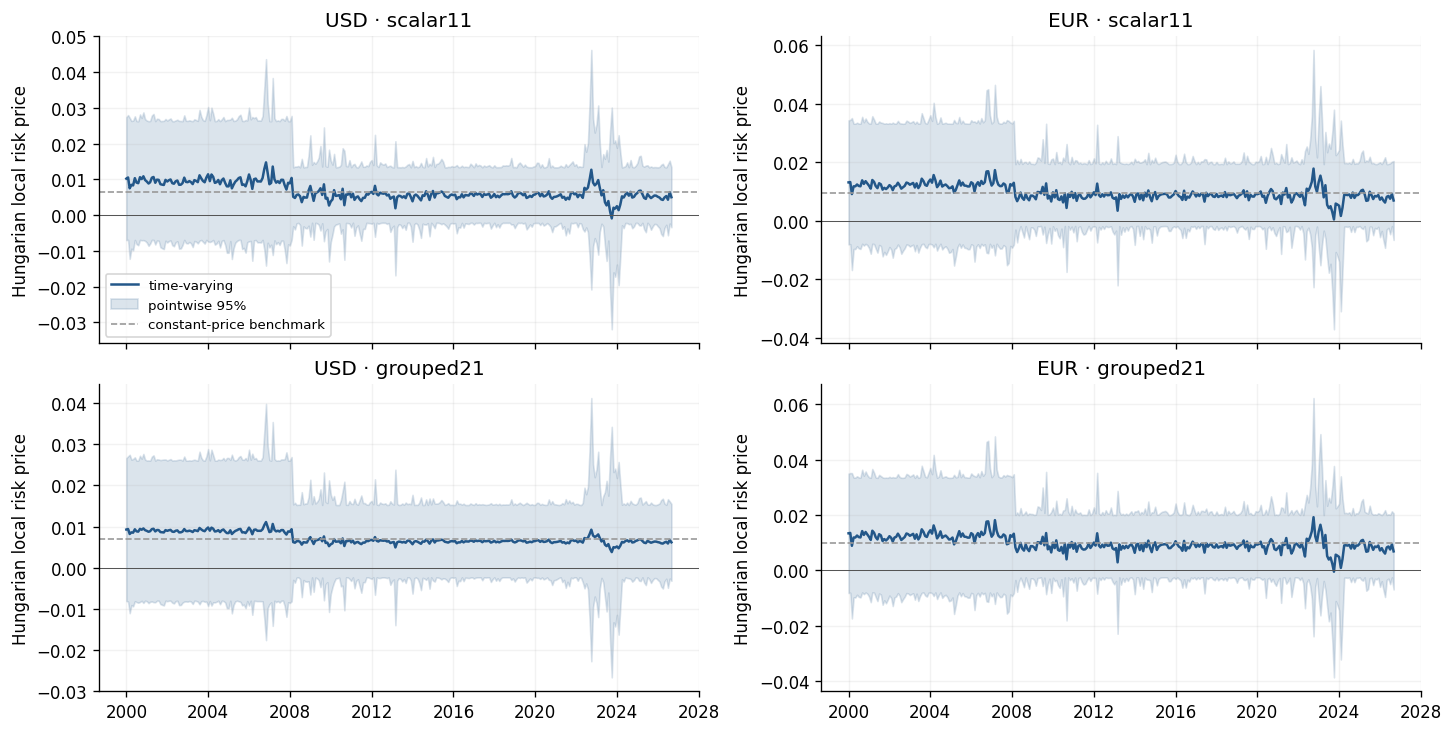

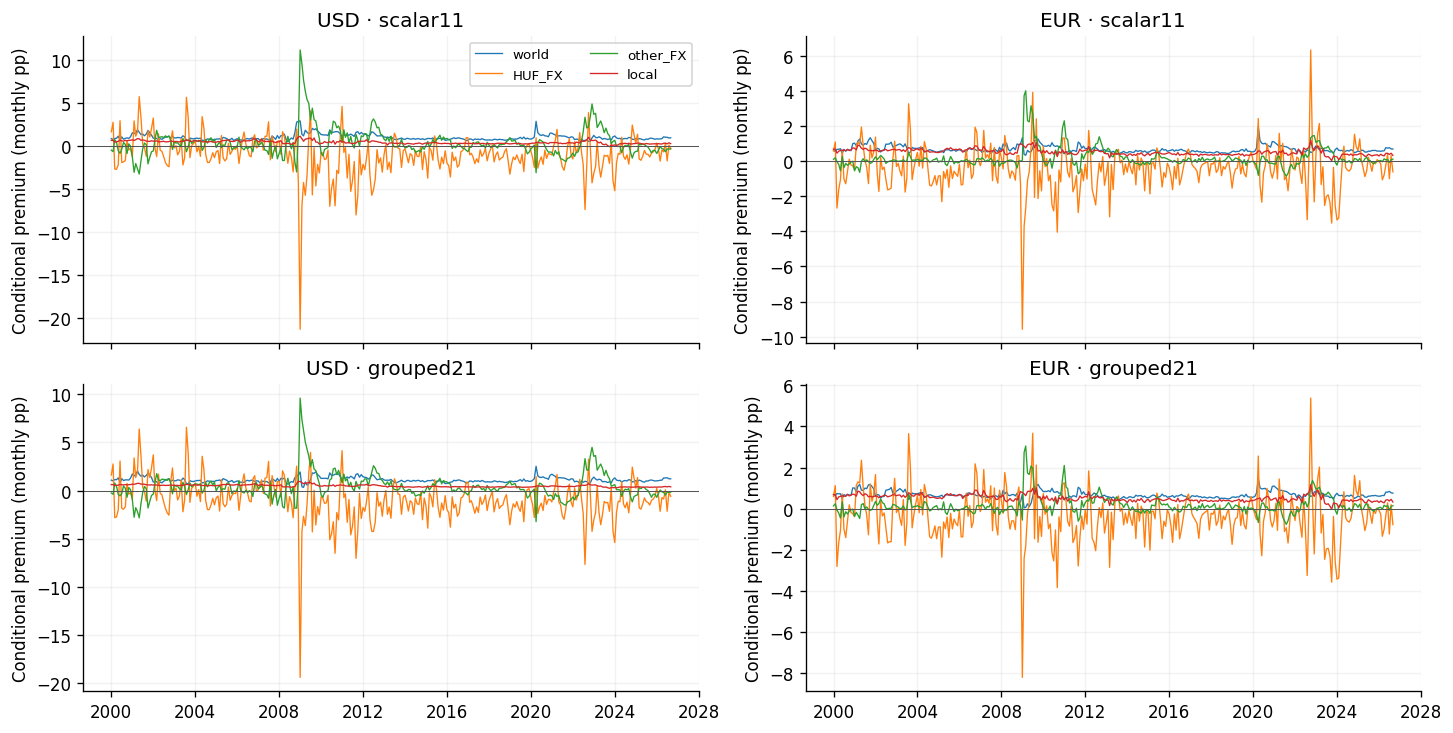

In [6]:
fig,axes=plt.subplots(len(COVARIANCE_MODELS),2,figsize=(12,3*len(COVARIANCE_MODELS)),sharex=True,layout="constrained",squeeze=False)
for col,currency in enumerate(["USD","EUR"]):
    for row,name in enumerate(COVARIANCE_MODELS):
        ax=axes[row,col];case=fits[f"{currency}_{name}_{LOCAL_INFLATION}"];f=case["filter"];idx=model.price_indices(case["pdesign"])["L"]
        V=case["inference"]["estimates"][0]["covariance"];z=case["pdesign"]["L"]
        path=f["local_prices"];dates=data.index.to_timestamp();ax.plot(dates,path,label="time-varying",color="#235789")
        if np.isfinite(V).all():
            se=base.PRICE_SCALE*np.sqrt(np.maximum(0,np.einsum("ti,ij,tj->t",z,V[np.ix_(idx,idx)],z)))
            ax.fill_between(dates,path-1.96*se,path+1.96*se,alpha=.16,color="#235789",label="pointwise 95%")
        ax.axhline(fits[f"{currency}_{name}_constant"]["filter"]["prices"][2],color="#999999",ls="--",lw=1,label="constant-price benchmark")
        ax.axhline(0,color="#555555",lw=.6);ax.set(title=f"{currency} · {name}",ylabel="Hungarian local risk price")
axes[0,0].legend(fontsize=8)
plt.savefig(OUT/"01_local_price_paths.png",dpi=160,bbox_inches="tight");plt.show();plt.close()
fig,axes=plt.subplots(len(COVARIANCE_MODELS),2,figsize=(12,3*len(COVARIANCE_MODELS)),sharex=True,layout="constrained",squeeze=False)
for col,currency in enumerate(["USD","EUR"]):
    for row,name in enumerate(COVARIANCE_MODELS):
        ax=axes[row,col];p=fits[f"{currency}_{name}_{LOCAL_INFLATION}"]["premia"]
        for label in ["world","HUF_FX","other_FX","local"]:ax.plot(data.index.to_timestamp(),p[label],lw=.8,label=label)
        ax.axhline(0,color="#555555",lw=.6);ax.set(title=f"{currency} · {name}",ylabel="Conditional premium (monthly pp)")
axes[0,0].legend(ncol=2,fontsize=8)
plt.savefig(OUT/"02_Hungary_premia.png",dpi=160,bbox_inches="tight");plt.show();plt.close()

## 6. Save reproducible outputs and the final summary

Save instrument audits/normalizers/quality flags, full designs, fit attempts, full joint uncertainty,
all restrictions and residual screens, fitted price paths and Hungary's premium decomposition.
The primary summary compares each time-varying local specification with its own constant-local
benchmark. The opposite gap transformation stays in a separate exploratory table.

In [7]:
tables={"instrument_audit.csv":instrument_audit,"local_design_audit.csv":design_audit,"mean_loading_audit.csv":mean_loading_audit,
    "local_instrument_normalizers.csv":local_normalizers,"local_conditioning_quality_flags.csv":local_quality,"starting_points.csv":starting_points,
    "fit_summary.csv":summary,"primary_summary.csv":main,"restriction_tests.csv":tests,"price_coefficients.csv":coefficients,
    "residual_diagnostics.csv":residuals,"cross_covariance_diagnostics.csv":cross_diagnostics,"premium_summary.csv":premium_summary}
for name,table in tables.items():table.to_csv(OUT/name)
for key,case in fits.items():
    f,inf=case["filter"],case["inference"]
    np.savez_compressed(OUT/f"parameters_{key}.npz",theta=case["theta"],H=f["H"],mu=f["mu"],residuals=f["errors"],scores=f["scores"],Hessian=inf["Hessian"],**{f"covariance_HAC{h}":v["covariance"] for h,v in inf["estimates"].items()})
    case["premia"].to_csv(OUT/f"premia_{key}.csv")
    pd.DataFrame({"world":f["world_prices"],"HUF_FX":f["fx_prices"][:,0],"other_FX":f["fx_prices"][:,1],"HU_local":f["local_prices"]},index=data.index).to_csv(OUT/f"price_paths_{key}.csv")
    for label,z in case["pdesign"].items():pd.DataFrame(z,index=data.index,columns=case["columns"][label]).to_csv(OUT/f"design_{key}_{label}.csv")
record={"model_version":MODEL_VERSION,"snapshot":SNAPSHOT,"source_dataset_sha256":manifest["exports"]["dataset.csv"],"first":str(data.index[0]),"last":str(data.index[-1]),"observations":len(data),
    "covariance_models":COVARIANCE_MODELS,"local_primary":LOCAL_INFLATION,"alternative_gap":RUN_ALTERNATIVE_GAP,"local_instruments":["inflation_gap_lag2","floating_regime_known"],
    "HAC_lags":HAC_LAGS,"test_lags":TEST_LAGS,"SE_step_tolerance":SE_STEP_TOL,"engines":engine_hashes,"upstream":UPSTREAM,"upstream_file_sha256":upstream_hashes,
    "conditioning_root":str(conditioning_root.relative_to(ROOT)),"conditioning_file_sha256":conditioning_hashes,"world_FX_instruments":prior["instrument_specification"],"python":platform.python_version(),"packages":versions}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
final_rows=[]
for key,row in summary[summary["local_specification"].ne("constant")].iterrows():
    record={"case":key,"primary":row["local_specification"]==LOCAL_INFLATION,"n":row["n"],"AIC_change":row["AIC_minus_constant"],"BIC_change":row["BIC_minus_constant"],"ready":row["sandwich_ready_all_lags"],"variance_flags":row["variance_flags"],"cross_flags":row["cross_flags"]}
    for h in HAC_LAGS:
        record[f"local_constancy_p_HAC{h}"]=tests.loc[(key,h,"Hungarian local price constant"),"robust_p_value"]
        record[f"FX_constancy_p_HAC{h}"]=tests.loc[(key,h,"FX prices constant"),"robust_p_value"]
    final_rows.append(record)
final_summary=pd.DataFrame(final_rows).set_index("case");final_summary.to_csv(OUT/"final_summary.csv")
discussion=final_summary[["primary","n","AIC_change","BIC_change","ready","variance_flags"]].copy()
for key in discussion.index:
    p=tests.xs((key,"Hungarian local price constant"),level=("case","test"))["robust_p_value"]
    discussion.loc[key,"local_constancy_p_HAC0"]=p.loc[0]
    discussion.loc[key,"local_constancy_p_min"]=p.min()
    discussion.loc[key,"local_constancy_p_max"]=p.max()
    discussion.loc[key,"local_zero_p_HAC0"]=tests.loc[(key,0,"Hungarian local price zero"),"robust_p_value"]
discussion.to_csv(OUT/"discussion_summary.csv")
display(Markdown("**Primary local-risk results — joint local constancy is the two-slope test; zero local pricing is the separate three-coefficient test**"))
display(discussion[discussion["primary"]].drop(columns="primary"))
primary_p=tests.loc[[(key,h,"Hungarian local price constant") for key in discussion[discussion["primary"]].index for h in HAC_LAGS],"robust_p_value"]
if primary_p.notna().all() and (primary_p>.05).all():
    display(Markdown(f"**Interpretation:** none of the primary local-constancy tests rejects at 5% across both perspectives, retained covariance models and fixed HAC bandwidths "
        f"(p-values **{primary_p.min():.4f}–{primary_p.max():.4f}**). We do not find support for the added local time variation with these instruments; "
        "this does not establish that the true local price is constant or zero."))
if (discussion.loc[discussion["primary"],["AIC_change","BIC_change"]]>0).all().all():
    display(Markdown("Both AIC and BIC favor each matched **constant-local-price benchmark** over the primary extension."))
if RUN_ALTERNATIVE_GAP:
    display(Markdown("**Exploratory opposite-gap transformation — world/FX conditioners unchanged**"));display(discussion[~discussion["primary"]].drop(columns="primary"))
display(premium_summary.round(5))
display(Markdown("Local time variation and zero local pricing are separate tests. Interpret them together with covariance diagnostics, "
    "identification checks, both retained covariance models and the gap transformation sensitivity. "
    "Pricing-error intercept tests and the final paper-style synthesis remain to be done. "
    f"Outputs: `{OUT.relative_to(ROOT)}`. The frozen dataset and upstream outputs were read without updating them."))

**Primary local-risk results — joint local constancy is the two-slope test; zero local pricing is the separate three-coefficient test**

,n,AIC_change,BIC_change,ready,variance_flags,local_constancy_p_HAC0,local_constancy_p_min,local_constancy_p_max,local_zero_p_HAC0
case,,,,,,,,,
USD_scalar11_change,321,3.65934,11.2022,True,4,0.828827,0.825791,0.845533,0.380267
USD_grouped21_change,321,3.89296,11.4358,True,1,0.949303,0.943071,0.949303,0.400963
EUR_scalar11_change,321,3.75072,11.2936,True,2,0.853224,0.853224,0.887612,0.285424
EUR_grouped21_change,321,3.72774,11.2706,True,0,0.835465,0.835465,0.876115,0.330152


**Interpretation:** none of the primary local-constancy tests rejects at 5% across both perspectives, retained covariance models and fixed HAC bandwidths (p-values **0.8258–0.9493**). We do not find support for the added local time variation with these instruments; this does not establish that the true local price is constant or zero.

Both AIC and BIC favor each matched **constant-local-price benchmark** over the primary extension.

**Exploratory opposite-gap transformation — world/FX conditioners unchanged**

,n,AIC_change,BIC_change,ready,variance_flags,local_constancy_p_HAC0,local_constancy_p_min,local_constancy_p_max,local_zero_p_HAC0
case,,,,,,,,,
USD_scalar11_level,321,2.88394,10.4268,True,4,0.612117,0.512074,0.672716,0.294841
USD_grouped21_level,321,2.92536,10.4682,True,1,0.593889,0.498634,0.66719,0.286605
EUR_scalar11_level,321,3.17709,10.72,True,2,0.692824,0.614418,0.745761,0.26425
EUR_grouped21_level,321,3.21243,10.7553,True,0,0.695714,0.625476,0.742425,0.307125


,mean_local_price,local_price_sd,mean_local_premium_pp,mean_total_premium_pp
case,,,,
USD_scalar11_constant,0.00653,0,0.44482,0.88154
USD_scalar11_change,0.00672,0.00231,0.45467,0.89587
USD_scalar11_level,0.00651,0.00412,0.44568,0.88706
USD_grouped21_constant,0.00707,0,0.47639,1.03068
USD_grouped21_change,0.00717,0.00134,0.48127,1.03919
USD_grouped21_level,0.00696,0.00402,0.47335,1.03375
EUR_scalar11_constant,0.00958,0,0.50289,0.92127
EUR_scalar11_change,0.0097,0.00247,0.50823,0.93092
EUR_scalar11_level,0.00949,0.00444,0.50287,0.92597


Local time variation and zero local pricing are separate tests. Interpret them together with covariance diagnostics, identification checks, both retained covariance models and the gap transformation sensitivity. Pricing-error intercept tests and the final paper-style synthesis remain to be done. Outputs: `output/10_time_varying_local/fixed_2026-11-13/2000-01_2026-09/local_change`. The frozen dataset and upstream outputs were read without updating them.